In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
import httpx
import plotly.express as px
import plotly.io as pio
import unidecode
import seaborn as sns

# Ingesta de Datos

In [12]:
df_bolsa_cereales_nacion = pd.read_excel("./data/datos_bolsa_cereales_nacion.csv")
df_bolsa_cereales_cba = pd.read_csv("./data/datos_bolsa_granos_cba.csv")
df_estimaciones_agricolas = pd.read_csv("./data/datos_estimaciones.csv",encoding="utf-8-sig")

# Preparacion de Indice de Cultivo

**NOTA**: Si bien los indices de cultivos al ser la proporción del rendimiento en grano respecto a la biomasa aérea total de la planta pueden variar por mejroas geneticas se suponen constantes y se utiliza los del paper como referencia

In [18]:
import pandas as pd

data = {
    "Cultivo": [
        "maíz", "soja", "trigo", "girasol", "maní", "garbanzo",
        "sorgo", "cebada", "centeno", "avena", "poroto",
        # Nuevos agregados
        "ajo",
        "colza",
        "papa",
        "lino",
        "arroz",
        "algodón"
    ],
    "IC": [
        0.47, 0.45, 0.35, 0.37, 0.40, 0.26,
        0.35, 0.53, 0.22, 0.35, 0.45,
        # Nuevos agregados
        0.55,   # ajo
        0.28,   # colza
        0.74,   # papa
        0.40,   # lino (valor representativo documentado)
        0.45,   # arroz (valor representativo del rango moderno)
        0.30    # algodón (lint HI representativo)
    ],
    "Fuente bibliográfica": [
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Raposo (2024)",
        "Haro (2022), Promedio variedad granoleico",
        "Promedio de lo obtenido por Apáez-Barrios (2017) y Ramacciotti (2015)",
        "Promedio de híbridos obtenido por Zamer y Chiarelli",
        "Cuda (2014)",
        "Zubiaga et al. (2023)",
        "Promedios obtenidos por Zubiaga et al. (2023)",
        "Ortega (2001)",
        # Nuevos agregados
        "Rizzalli, Villalobos & Orgaz (2002). European Journal of Agronomy",
        "Unkovich et al. / Advances in Agronomy (compilado ~2010); Lu et al. (2016)",
        "Xu et al. (análisis QUEFTS, Agronomy Journal); rango documentado 0.70-0.85",
        "Estudios de componentes de rendimiento (ADAS/AHDB y ensayos de monocultivo)",
        "Hay (1995) y estudios recientes de riego/N (rango moderno 0.40-0.55)",
        "Estudios regionales (Xinjiang y revisiones globales de lint HI)"
    ]
}

df_IC = pd.DataFrame(data)

df_IC['FR'] = (1 - df_IC['IC']) / df_IC['IC']

df_IC.head(20)

,Cultivo,IC,Fuente bibliográfica,FR
0,maíz,0.47,Bolsa de Cereales de Buenos Aires (2015),1.127660
1,soja,0.45,Bolsa de Cereales de Buenos Aires (2015),1.222222
2,trigo,0.35,Bolsa de Cereales de Buenos Aires (2015),1.857143
3,girasol,0.37,Raposo (2024),1.702703
4,maní,0.40,"Haro (2022), Promedio variedad granoleico",1.500000
5,garbanzo,0.26,Promedio de lo obtenido por Apáez-Barrios (201...,2.846154
6,sorgo,0.35,Promedio de híbridos obtenido por Zamer y Chia...,1.857143
7,cebada,0.53,Cuda (2014),0.886792
8,centeno,0.22,Zubiaga et al. (2023),3.545455
9,avena,0.35,Promedios obtenidos por Zubiaga et al. (2023),1.857143


### Markdown de aclaración (cultivos agregados + fuentes con links)

| Cultivo   | IC usado | Fuente y link |
|-----------|----------|---------------|
| **ajo**   | 0.55    | Rizzalli, R.H.; Villalobos, F.J.; Orgaz, F. (2002). *Radiation interception, radiation-use efficiency and dry matter partitioning in garlic (Allium sativum L.)*. European Journal of Agronomy 18(1-2): 33-43. HI reportado ≈0.55.<br>Link: https://www.sciencedirect.com/science/article/abs/pii/S1161030102000941<br>También respaldado por Escalante-Estrada et al. (2019) Terra Latinoamericana (IC ≈0.66–0.69 / 68%). |
| **colza** | 0.28    | Unkovich et al. (compilado en Advances in Agronomy) y Lu et al. (2016). Media ≈0.28 (rango documentado 0.04–0.42, típico 0.20–0.28).<br>Link de referencia: https://www.sciencedirect.com/science/article/abs/pii/S0378429016306840 y estudios de *Brassica napus* citados en PMC (ej. https://pmc.ncbi.nlm.nih.gov/articles/PMC6507709/). |
| **papa**  | 0.74    | Xu et al. (análisis QUEFTS en China, n=654). Media 0.74 (rango 0.40–0.95; 95% entre 0.52–0.87). Valores frecuentes 0.70–0.85 en literatura.<br>Link: https://acsess.onlinelibrary.wiley.com/doi/abs/10.2134/agronj2018.09.0572 |
| **lino**  | 0.40    | Valores documentados en ensayos de componentes de rendimiento (≈0.38) y monocultivos (hasta ≈0.51). Se usó 0.40 como representativo del rango reportado.<br>Referencias: estudios ADAS/AHDB y papers de *Linum usitatissimum* (ej. diversidad de HI en mezclas: https://pmc.ncbi.nlm.nih.gov/articles/PMC7611346/). |
| **arroz** | 0.45    | Rango moderno documentado 0.34–0.55 (frecuentemente 0.40–0.55; algunos ensayos ≥0.55–0.62). Se usó 0.45 como valor central representativo.<br>Fuente clásica: Hay (1995) Annals of Applied Biology + estudios recientes de riego/N. |
| **algodón** | 0.30  | Lint harvest index típico en regiones áridas ≈0.28–0.33 (Xinjiang); rangos globales más amplios. Se usó 0.30 como representativo.<br>Link: https://doi.org/10.3390/agronomy15030743 |

**Notas importantes:**
- No se agregaron cultivos sin dato confiable (alpiste, jojoba, yerba mate, tung, té, banana, cítricos, caña de azúcar, cebolla con IC estándar, etc.).
- Los valores de IC originales de la tabla se mantuvieron intactos.
- El cálculo de `FR` se aplica automáticamente a todos los registros (incluyendo los nuevos).

# Tratamiento de Datos

## Conversion de Unidades

1. La produccion tiene que quedar en Tn  
2. La Superficie tiene que quedar en Ha 
3. El Rendimiento debe quedar expresado en Tn para que la Biomasa Residual quede en Tn

### Bolsa de Datos Nacion

In [7]:
df_bolsa_cereales_nacion.head()

,Campaña,Zona,Cultivo,Sembrado (Ha),Perdído(Ha),Cosechado(Ha),Rinde(qq/Ha),Producción(MTn)
0,2026/2027,TOTAL,Trigo,6500000,0,0,0.0,0
1,2026/2027,TOTAL,Maíz,8400000,0,0,0.0,0
2,2026/2027,TOTAL,Girasol,3000000,0,0,0.0,0
3,2026/2027,TOTAL,Cebada,1270000,0,0,0.0,0
4,2025/2026,NOA,Trigo,322000,19300,302700,11.3,340986


Realizamos los siguientes conversiones
1. Pasamos Produccion de Mtn a tn, se realiza multiplicando por 1000
2. Pasamos Rinde de (qq/Ha) a tn. Esto se realiza para obtener la biomasa residual en toneladas. Tener en cuenta que rendimiento es la division de Produccion entre cosechado.

In [8]:
df_bolsa_cereales_nacion["Producción (Ton)"] = df_bolsa_cereales_nacion["Producción(MTn)"] / 1000
df_bolsa_cereales_nacion["Rinde (Ton)"] = (df_bolsa_cereales_nacion["Rinde(qq/Ha)"] * 0.1) * df_bolsa_cereales_nacion["Cosechado(Ha)"]
df_bolsa_cereales_nacion.head()

,Campaña,Zona,Cultivo,Sembrado (Ha),Perdído(Ha),Cosechado(Ha),Rinde(qq/Ha),Producción(MTn),Producción (Ton),Rinde (Ton)
0,2026/2027,TOTAL,Trigo,6500000,0,0,0.0,0,0.000,0.0
1,2026/2027,TOTAL,Maíz,8400000,0,0,0.0,0,0.000,0.0
2,2026/2027,TOTAL,Girasol,3000000,0,0,0.0,0,0.000,0.0
3,2026/2027,TOTAL,Cebada,1270000,0,0,0.0,0,0.000,0.0
4,2025/2026,NOA,Trigo,322000,19300,302700,11.3,340986,340.986,342051.0


### Estimaciones Agricolas

Las superficies se muestran en hectáreas, la producción en toneladas y el rendimiento en kg/ha.
Por lo tanto vamos a realizar las siguientes conversiones:

1. Pasar el rendimiento a toneladas multiplicando el rendimiento por las hectarias de superficie cosechada y dividiendo por 1000 (ha/1000)

In [9]:
df_estimaciones_agricolas.info()

<class 'pandas.DataFrame'>
RangeIndex: 127906 entries, 0 to 127905
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   Cultivo         127906 non-null  str  
 1   Campaña         127906 non-null  str  
 2   Provincia       127906 non-null  str  
 3   Departamento    127906 non-null  str  
 4   idProvincia     127906 non-null  int64
 5   idDepartamento  127906 non-null  int64
 6   Sup. Sembrada   127906 non-null  str  
 7   Sup. Cosechada  127906 non-null  str  
 8   Producción      127906 non-null  str  
 9   Rendimiento     127906 non-null  str  
dtypes: int64(2), str(8)
memory usage: 9.8 MB


In [10]:
# Convertimos a numerico las columnas de superficie sembrada, cosechada, produccion y rendimiento

cols = ["Sup. Sembrada", "Sup. Cosechada", "Producción", "Rendimiento"]

# Convertir a numérico, forzando errores a NaN si hay valores no válidos
for c in cols:
    df_estimaciones_agricolas[c] = pd.to_numeric(df_estimaciones_agricolas[c].str.replace(".", "", regex=False)  # quita separador de miles
                               .str.replace(",", ".", regex=False), # cambia coma decimal por punto
                          errors="coerce")


In [11]:
df_estimaciones_agricolas["Rendimiento (Tn)"] = (df_estimaciones_agricolas["Rendimiento"] / 1000) * df_estimaciones_agricolas["Sup. Cosechada"]
df_estimaciones_agricolas.head()

,Cultivo,Campaña,Provincia,Departamento,idProvincia,idDepartamento,Sup. Sembrada,Sup. Cosechada,Producción,Rendimiento,Rendimiento (Tn)
0,Ajo,1969/70,BUENOS AIRES,25 DE MAYO,6,854,3.0,3.0,10.0,3333.0,9.999
1,Ajo,1970/71,BUENOS AIRES,25 DE MAYO,6,854,1.0,1.0,3.0,3000.0,3.000
2,Alpiste,1969/70,BUENOS AIRES,25 DE MAYO,6,854,500.0,400.0,240.0,600.0,240.000
3,Alpiste,1970/71,BUENOS AIRES,25 DE MAYO,6,854,150.0,130.0,78.0,600.0,78.000
4,Alpiste,1975/76,BUENOS AIRES,25 DE MAYO,6,854,350.0,350.0,315.0,900.0,315.000


### Bolsa de Datos CBA

en este caso la superficie sembrada se encuetra en hectareas, la produccion ya esta en Tn y el rendimiento en qq/ha por lo que solo hay que convertir el rendimiento a toneladas

In [12]:
df_bolsa_cereales_cba.head()

,PROVINCIA,DEPARTAMENTO,CULTIVO,CAMPAÑA,SEMBRADAS,COSECHADAS,RENDIMIENTO,RENDIMIENTO GRANO LIMPIO Y SECO,PRODUCCIÓN,PRODUCCIÓN GRANO LIMPIO Y SECO
0,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,11.0,165.652347,79.0
1,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,11.0,165.652347,2785.0
2,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,24.0,165.652347,79.0
3,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,24.0,165.652347,2785.0
4,Buenos Aires,9 DE JULIO,MANI,2020/21,153.323501,150.257031,39.092,24.0,587.384785,354.0


In [13]:
df_bolsa_cereales_cba["Rinde (Ton)"] = (df_bolsa_cereales_cba["RENDIMIENTO"] * 0.1) * df_bolsa_cereales_cba["COSECHADAS"]
df_bolsa_cereales_cba.head()

,PROVINCIA,DEPARTAMENTO,CULTIVO,CAMPAÑA,SEMBRADAS,COSECHADAS,RENDIMIENTO,RENDIMIENTO GRANO LIMPIO Y SECO,PRODUCCIÓN,PRODUCCIÓN GRANO LIMPIO Y SECO,Rinde (Ton)
0,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,11.0,165.652347,79.0,165.652347
1,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,11.0,165.652347,2785.0,165.652347
2,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,24.0,165.652347,79.0,165.652347
3,Buenos Aires,25 DE MAYO,MANI,2022/23,75.296522,75.296522,22.000,24.0,165.652347,2785.0,165.652347
4,Buenos Aires,9 DE JULIO,MANI,2020/21,153.323501,150.257031,39.092,24.0,587.384785,354.0,587.384785


## Unificacion de datasets

In [14]:
# Encabezados
print(f"{'Bolsa de Cereales Nacion':<30} | Columnas")
print(" | ".join(df_bolsa_cereales_nacion.columns))
print()

print(f"{'Bolsa de Cereales CBA':<30} | Columnas")
print(" | ".join(df_bolsa_cereales_cba.columns))
print()

print(f"{'Estimaciones Agricolas':<30} | Columnas")
print(" | ".join(df_estimaciones_agricolas.columns))


Bolsa de Cereales Nacion       | Columnas
Campaña | Zona | Cultivo | Sembrado (Ha) | Perdído(Ha) | Cosechado(Ha) | Rinde(qq/Ha) | Producción(MTn) | Producción (Ton) | Rinde (Ton)

Bolsa de Cereales CBA          | Columnas
PROVINCIA | DEPARTAMENTO | CULTIVO | CAMPAÑA | SEMBRADAS | COSECHADAS | RENDIMIENTO | RENDIMIENTO GRANO LIMPIO Y SECO | PRODUCCIÓN | PRODUCCIÓN GRANO LIMPIO Y SECO | Rinde (Ton)

Estimaciones Agricolas         | Columnas
Cultivo | Campaña | Provincia | Departamento | idProvincia | idDepartamento | Sup. Sembrada | Sup. Cosechada | Producción | Rendimiento | Rendimiento (Tn)


Nos vamos a quedar con las columnas: Provincia, Campaña, Cultivo, Superficie, Produccion, Rendimiento

**NOTA**: 
1. Superficie sembrada, Produccion quedaran para la siguiente iteracion 
2. Supongo que el redimiento en todos los DF estan expresados en quintales por hectarea (qq/Ha)
3. Desestimo el uso del Dataset de estimacion agricolas por falta de la columna Provincia

In [15]:
# --- Normalización de columnas ---

# df_bolsa_cereales_nacion
df_nacion = df_bolsa_cereales_nacion.rename(
    columns={
        "Zona": "Provincia",
        "Campaña": "Campaña",
        "Cultivo": "Cultivo",
        "Cosechado(Ha)" : "Superficie(Ha)",
        "Producción (Ton)" : "Produccion(Tn)",
        "Rinde (Ton)": "Rendimiento(Tn)"
    }
)[["Provincia", "Campaña", "Cultivo", "Superficie(Ha)", "Produccion(Tn)", "Rendimiento(Tn)"]]

# df_bolsa_cereales_cba
df_cba = df_bolsa_cereales_cba.rename(
    columns={
        "PROVINCIA": "Provincia",
        "CAMPAÑA": "Campaña",
        "CULTIVO": "Cultivo",
        "COSECHADAS": "Superficie(Ha)",
        "PRODUCCIÓN": "Produccion(Tn)",
        "Rinde (Ton)": "Rendimiento(Tn)"
    }
)[["Provincia", "Campaña", "Cultivo", "Superficie(Ha)", "Produccion(Tn)", "Rendimiento(Tn)"]]

# df_estimaciones_agricolas
df_estimaciones = df_estimaciones_agricolas.rename(
    columns={
        "Provincia": "Provincia",
        "Campaña": "Campaña",
        "Cultivo": "Cultivo",
        "Sup. Cosechada": "Superficie(Ha)",
        "Producción": "Produccion(Tn)",
        "Rendimiento (Tn)": "Rendimiento(Tn)"
    }
)[["Provincia", "Campaña", "Cultivo", "Superficie(Ha)", "Produccion(Tn)", "Rendimiento(Tn)"]]

# --- Unión de los tres ---
df_concat = pd.concat([df_nacion, df_cba, df_estimaciones], ignore_index=True)

In [16]:
df_concat.head()

,Provincia,Campaña,Cultivo,Superficie(Ha),Produccion(Tn),Rendimiento(Tn)
0,TOTAL,2026/2027,Trigo,0.0,0.000,0.0
1,TOTAL,2026/2027,Maíz,0.0,0.000,0.0
2,TOTAL,2026/2027,Girasol,0.0,0.000,0.0
3,TOTAL,2026/2027,Cebada,0.0,0.000,0.0
4,NOA,2025/2026,Trigo,302700.0,340.986,342051.0


## Valores Nulos

In [17]:
df_concat.isnull().sum()

Provincia             0
Campaña               0
Cultivo               0
Superficie(Ha)     3158
Produccion(Tn)      256
Rendimiento(Tn)    3402
dtype: int64

Observamos que tanto en cultimo como en campaña, provincia y rendimiento tenemos nulos, daod que no podemos tolerar nulos en ninguna columna porque todas son criticas debemos eliminar todos las filas que contengan algun nilo

In [18]:
df_cleaned = df_concat.dropna(how="any")

In [19]:
df_cleaned.isnull().sum()

Provincia          0
Campaña            0
Cultivo            0
Superficie(Ha)     0
Produccion(Tn)     0
Rendimiento(Tn)    0
dtype: int64

## Normalización de Columnas

### Cultivo

In [20]:
conteo = df_cleaned["Cultivo"].value_counts(dropna=False)

conteo.loc["TOTAL"] = len(df_cleaned)

print(conteo)

Cultivo
Trigo total          13369
Sorgo                12212
Soja total           11818
Avena                11609
Girasol              11092
Cebada forrajera      6468
Centeno               6101
Papa total            5530
Cebada cervecera      4378
Cebolla total         4334
Algodón               4244
Lino                  4006
Ajo                   4000
Poroto total          2746
Mijo                  2610
Alpiste               2298
Arroz                 2116
Naranja               2019
Maní                  2015
Colza                 1698
Mandarina             1670
Limón                 1515
Pomelo                1394
Trigo candeal         1277
Caña de azúcar        1267
Yerba mate            1069
Té                    1006
MAIZ                   758
SOJA                   754
TRIGO                  707
Tung                   681
SORGO                  517
Cártamo                514
MANI                   492
Trigo                  351
Soja                   350
GIRASOL             

Se Observa dumplicacion de columnas como  con SOJA y soja asi como TRIGO y trigo o MAIZ y maiz o SORGO y Sorgo entre otras se proces a Normalizar las Categorias

In [21]:
df_cleaned["Cultivo"] = df_cleaned["Cultivo"].str.replace(" total", "", regex=False)

df_cleaned["Cultivo"] = df_cleaned["Cultivo"].str.lower().str.strip()

conteo = df_cleaned["Cultivo"].value_counts(dropna=False)

conteo.loc["TOTAL"] = len(df_cleaned)

print(conteo)

Cultivo
trigo                14427
soja                 12922
sorgo                12743
avena                11609
girasol              11436
cebada forrajera      6468
centeno               6101
papa                  5530
cebada cervecera      4378
cebolla               4334
algodón               4244
lino                  4006
ajo                   4000
poroto                2746
mijo                  2610
alpiste               2298
arroz                 2116
naranja               2019
maní                  2015
colza                 1698
mandarina             1670
limón                 1515
pomelo                1394
trigo candeal         1314
caña de azúcar        1267
yerba mate            1069
té                    1006
maiz                   758
tung                   681
cártamo                514
mani                   492
maíz                   343
banana                 280
cebada                 249
garbanzo               227
jojoba                  20
TOTAL               

### Capaña

vamos a utilizar el formato YYYY/YY como el formato estandar de nuestra columan campaña

In [22]:
# Patrón correcto: 4 dígitos / 2 dígitos (ej. 2024/25)
pattern = r"^\d{4}/\d{2}$"

# Filtrar filas que NO cumplen el patrón
invalid_values = df_cleaned.loc[~df_cleaned["Campaña"].str.match(pattern, na=False), "Campaña"]

print("Cantidad de valores fuera de formato YYYY/YY: ", len(invalid_values))

Cantidad de valores fuera de formato YYYY/YY:  1901


Observamos que algunos valores no respetan el formato YYYY/YY sino que tienen formato YYYY/YYYY procedemos a normalizar el formato

In [23]:
# Transformación de la columna "Campaña"
df_cleaned["Campaña"] = df_cleaned["Campaña"].str.replace(
    r"(\d{4})/(\d{2})\d{2}",  # patrón: YYYY/YY?? (ej. 2024/2025)
    r"\1/\2",                 # reemplazo: YYYY/YY
    regex=True
)

invalid_values = df_cleaned.loc[~df_cleaned["Campaña"].str.match(pattern, na=False), "Campaña"]

print("Cantidad de valores fuera de formato YYYY/YY: ", len(invalid_values))

Cantidad de valores fuera de formato YYYY/YY:  0


### Provincia

In [24]:
Provincia = df_cleaned["Provincia"].value_counts(dropna=False)

Provincia.loc["TOTAL"] = len(df_cleaned)

print(Provincia)

Provincia
BUENOS AIRES            41381
SANTA FE                 9662
CORDOBA                  8999
CHACO                    7201
LA PAMPA                 7119
ENTRE RIOS               7025
CORRIENTES               6533
MISIONES                 6339
SANTIAGO DEL ESTERO      5126
SALTA                    4958
TUCUMAN                  4238
SAN LUIS                 2738
JUJUY                    2455
MENDOZA                  2279
Córdoba                  2034
FORMOSA                  1914
CATAMARCA                1812
SAN JUAN                 1738
RIO NEGRO                 967
CHUBUT                    763
Santiago del Estero       721
NEUQUEN                   682
SANTA CRUZ                532
La Pampa                  479
LA RIOJA                  278
San Luis                  263
Tucumán                   205
TOTAL                  130499
Núcleo Norte              136
Núcleo Sur                136
Ctro BA                   136
SO BA-S LP                136
SE BA                     136


In [25]:
df_norm = df_cleaned.copy()

# Diccionario de normalización exacta
mapa_provincias = {
    "Córdoba": "Cordoba",
    "Cordoba": "Cordoba",
    "Catamarca": "Catamarca",
    "Tucumán": "Tucuman",
    "Tucuman": "Tucuman",
    "La Pampa": "La Pampa",
    "San Luis": "San Luis",
    "SL": "San Luis",
    "Santiago del Estero": "Santiago del Estero",
    "Buenos Aires": "Buenos Aires",
    "Entre Rios": "Entre Rios",
    "Santa Fe": "Santa Fe",
    # Provincias que pueden faltar en tu dataset pero deben estar presentes
    "Chaco": "Chaco",
    "Corrientes": "Corrientes",
    "Formosa": "Formosa",
    "Misiones": "Misiones",
    "Jujuy": "Jujuy",
    "Salta": "Salta",
    "La Rioja": "La Rioja",
    "San Juan": "San Juan",
    "Mendoza": "Mendoza",
    "Neuquén": "Neuquen",
    "Rio Negro": "Rio Negro",
    "Chubut": "Chubut",
    "Santa Cruz": "Santa Cruz",
    "Tierra del Fuego": "Tierra del Fuego"
}

# Reemplazo exacto
df_norm["Provincia"] = df_norm["Provincia"].replace(mapa_provincias)

# Reglas con regex seguras
df_norm.loc[df_norm["Provincia"].str.contains(r"\bcba\b", case=False, na=False), "Provincia"] = "Cordoba"
df_norm.loc[df_norm["Provincia"].str.contains(r"\bBA\b", case=False, na=False), "Provincia"] = "Buenos Aires"
df_norm.loc[df_norm["Provincia"].str.contains(r"\bER\b", case=False, na=False), "Provincia"] = "Entre Rios"
df_norm.loc[df_norm["Provincia"].str.contains("Sta Fe", case=False, na=False), "Provincia"] = "Santa Fe"
df_norm.loc[df_norm["Provincia"].str.contains("Cuenca Sal", case=False, na=False), "Provincia"] = "Buenos Aires"

# Filtrar: eliminar filas que no son provincias
zonas_invalidas = ["TOTAL", "Núcleo Norte", "Núcleo Sur", "Ctro BA", "SO BA-S LP",
                   "SE BA", "Ctro E ER", "Centro N Cba", "S Cba", "N LP-O BA",
                   "Centro N Sta Fe", "NEA", "NOA", "Cuenca Sal", "Otras"]

df_norm = df_norm[~df_norm["Provincia"].isin(zonas_invalidas)]

# Poner Todos los valores en minusculas
df_norm["Provincia"] = df_norm["Provincia"].str.lower()

# Validar: ver todas las provincias presentes
print(sorted(df_norm["Provincia"].unique()))

print(len(df_norm["Provincia"].unique()))


['buenos aires', 'catamarca', 'chaco', 'chubut', 'cordoba', 'corrientes', 'entre rios', 'formosa', 'jujuy', 'la pampa', 'la rioja', 'mendoza', 'misiones', 'neuquen', 'rio negro', 'salta', 'san juan', 'san luis', 'santa cruz', 'santa fe', 'santiago del estero', 'tierra del fuego', 'tucuman']
23


# Casting

### Produccion

In [26]:
print(df_norm.isnull().sum())
df_norm.info()

Provincia          0
Campaña            0
Cultivo            0
Superficie(Ha)     0
Produccion(Tn)     0
Rendimiento(Tn)    0
dtype: int64
<class 'pandas.DataFrame'>
Index: 129779 entries, 6 to 133900
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Provincia        129779 non-null  str    
 1   Campaña          129779 non-null  str    
 2   Cultivo          129779 non-null  str    
 3   Superficie(Ha)   129779 non-null  float64
 4   Produccion(Tn)   129779 non-null  float64
 5   Rendimiento(Tn)  129779 non-null  float64
dtypes: float64(3), str(3)
memory usage: 6.9 MB


### Indice de Cosecha

In [27]:
print(df_IC.isnull().sum())
df_IC.info()

Cultivo                 0
IC                      0
Fuente bibliográfica    0
FR                      0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Cultivo               11 non-null     str    
 1   IC                    11 non-null     float64
 2   Fuente bibliográfica  11 non-null     str    
 3   FR                    11 non-null     float64
dtypes: float64(2), str(2)
memory usage: 484.0 bytes


No es Necesario hacer conversiones

# Calculo de Biomasa Residual

En esta sección vamos a calcular la **biomasa residual** de los cultivos a partir del rendimiento y el índice de cosecha (IC).  

1. **Biomasa Residual**: $Biomasa Residual = Rendimiento \times FR$

2. **Factor de Residuo (FR)**: $FR = \frac{1 - IC}{IC}$

3. **Biomasa Residual**: $Biomasa\ Residual = Rendimiento \times \frac{1 - IC}{IC}$

**NOTA**: Adicionalmente, se calculará la **masa residual por provincia y por cultivo**, permitiendo comparar la generación de biomasa en diferentes regiones agrícolas.

In [28]:
df_norm.head()

,Provincia,Campaña,Cultivo,Superficie(Ha),Produccion(Tn),Rendimiento(Tn)
6,cordoba,2025/20,trigo,546900.0,2221.702,2220414.0
7,cordoba,2025/20,trigo,237000.0,911.036,910080.0
8,santa fe,2025/20,trigo,546700.0,2032.318,2033724.0
11,entre rios,2025/20,trigo,543200.0,2454.981,2455264.0
12,buenos aires,2025/20,trigo,447100.0,2342.557,2342804.0


In [ ]:
# Normalizar Cultivo en ambos DataFrames
df_norm["Cultivo"] = df_norm["Cultivo"].str.strip().str.lower().apply(unidecode.unidecode)
df_IC["Cultivo"]   = df_IC["Cultivo"].str.strip().str.lower().apply(unidecode.unidecode)

# Agrupar por Provincia Cultivo y Campaña calculando el promedio del rendimiento

df_biomasa = df_norm.groupby(["Provincia", "Cultivo", "Campaña"])[["Superficie(Ha)",	"Produccion(Tn)", "Rendimiento(Tn)"]].mode().reset_index()

# calculamos la biomasa residual para cada entrada de la tabla 

# 2. Merge (left) para traer el FR al df de rendimientos
df_biomasa = df_biomasa.merge(df_IC[['Cultivo', 'FR']], on='Cultivo', how='left')

# 3. Calcular el residuo (vectorizado)
df_biomasa['Residuo de Biomasa(Tn)'] = df_biomasa['Rendimiento(Tn)'] * df_biomasa['FR']

# Opcional: ordenar columnas y limpiar
df_biomasa = df_biomasa[['Provincia', 'Cultivo', 'Campaña', 'Superficie(Ha)', 'Produccion(Tn)', 'Residuo de Biomasa(Tn)']]

df_biomasa.info()

<class 'pandas.DataFrame'>
RangeIndex: 11386 entries, 0 to 11385
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Provincia               11386 non-null  str    
 1   Cultivo                 11386 non-null  str    
 2   Campaña                 11386 non-null  str    
 3   Superficie(Ha)          11386 non-null  float64
 4   Produccion(Tn)          11386 non-null  float64
 5   Residuo de Biomasa(Tn)  5614 non-null   float64
dtypes: float64(3), str(3)
memory usage: 533.8 KB


In [30]:
df_biomasa.dropna(how="any",inplace=True)
df_biomasa.info()

<class 'pandas.DataFrame'>
Index: 5614 entries, 86 to 11370
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Provincia               5614 non-null   str    
 1   Cultivo                 5614 non-null   str    
 2   Campaña                 5614 non-null   str    
 3   Superficie(Ha)          5614 non-null   float64
 4   Produccion(Tn)          5614 non-null   float64
 5   Residuo de Biomasa(Tn)  5614 non-null   float64
dtypes: float64(3), str(3)
memory usage: 307.0 KB


In [31]:
df_biomasa.head()

,Provincia,Cultivo,Campaña,Superficie(Ha),Produccion(Tn),Residuo de Biomasa(Tn)
86,buenos aires,avena,1969/70,2827.619048,3828.571429,7110.310204
87,buenos aires,avena,1970/71,2547.142857,3198.095238,5939.325034
88,buenos aires,avena,1971/72,3010.476190,4202.380952,7804.478367
89,buenos aires,avena,1972/73,3231.067961,4975.728155,9240.416588
90,buenos aires,avena,1973/74,3318.627451,4859.313725,9024.477101


# Densidades 

## Densidad de Biomadas

In [36]:
df_biomasa["Densidad de Residuo de Biomasa(Tn/Ha)"] = df_biomasa["Residuo de Biomasa(Tn)"] / df_biomasa["Superficie(Ha)"]
df_biomasa.head()

,Provincia,Cultivo,Campaña,Superficie(Ha),Produccion(Tn),Residuo de Biomasa(Tn),Densidad de Residuo de Biomasa(Tn/Ha)
86,buenos aires,avena,1969/70,2827.619048,3828.571429,7110.310204,2.514593
87,buenos aires,avena,1970/71,2547.142857,3198.095238,5939.325034,2.331760
88,buenos aires,avena,1971/72,3010.476190,4202.380952,7804.478367,2.592440
89,buenos aires,avena,1972/73,3231.067961,4975.728155,9240.416588,2.859865
90,buenos aires,avena,1973/74,3318.627451,4859.313725,9024.477101,2.719340


## Densidad de Produccion

In [53]:
df_biomasa["Densidad de Produccion(Tn/Ha)"] = df_biomasa["Produccion(Tn)"] / df_biomasa["Superficie(Ha)"]
df_biomasa.head()

,Provincia,Cultivo,Campaña,Superficie(Ha),Produccion(Tn),Residuo de Biomasa(Tn),Densidad de Residuo de Biomasa(Tn/Ha),Densidad de Produccion(Tn/Ha)
86,buenos aires,avena,1969/70,2827.619048,3828.571429,7110.310204,2.514593,1.353991
87,buenos aires,avena,1970/71,2547.142857,3198.095238,5939.325034,2.331760,1.255562
88,buenos aires,avena,1971/72,3010.476190,4202.380952,7804.478367,2.592440,1.395919
89,buenos aires,avena,1972/73,3231.067961,4975.728155,9240.416588,2.859865,1.539964
90,buenos aires,avena,1973/74,3318.627451,4859.313725,9024.477101,2.719340,1.464254


# Informe por departamentos 

In [ ]:
df_estimaciones_agricolas.head()

,Cultivo,Campaña,Provincia,Departamento,idProvincia,idDepartamento,Sup. Sembrada,Sup. Cosechada,Producción,Rendimiento,Rendimiento (Tn)
0,Ajo,1969/70,BUENOS AIRES,25 DE MAYO,6,854,3.0,3.0,10.0,3333.0,9.999
1,Ajo,1970/71,BUENOS AIRES,25 DE MAYO,6,854,1.0,1.0,3.0,3000.0,3.000
2,Alpiste,1969/70,BUENOS AIRES,25 DE MAYO,6,854,500.0,400.0,240.0,600.0,240.000
3,Alpiste,1970/71,BUENOS AIRES,25 DE MAYO,6,854,150.0,130.0,78.0,600.0,78.000
4,Alpiste,1975/76,BUENOS AIRES,25 DE MAYO,6,854,350.0,350.0,315.0,900.0,315.000


## Cultivos Del departamenteo Pedernera San Luis

In [ ]:
cultivos = (
    df_estimaciones_agricolas.loc[
        (df_estimaciones_agricolas["Provincia"] == "SAN LUIS")
        & (df_estimaciones_agricolas["Departamento"] == "GENERAL PEDERNERA"),
        "Cultivo"
    ]
    .str.replace(" total", "", regex=False)  # limpiar antes
    .unique()
)
cultivos_pedernera = sorted(cultivos)
print(cultivos_pedernera)

['Ajo', 'Avena', 'Cebada cervecera', 'Cebada forrajera', 'Cebolla', 'Centeno', 'Colza', 'Cártamo', 'Girasol', 'Maní', 'Mijo', 'Naranja', 'Papa', 'Poroto', 'Soja', 'Sorgo', 'Trigo']


In [ ]:
cultivos = (
    df_estimaciones_agricolas.loc[
        (df_estimaciones_agricolas["Provincia"] == "CORDOBA")
        & (df_estimaciones_agricolas["Departamento"] == "RIO CUARTO"),
        "Cultivo"
    ]
    .str.replace(" total", "", regex=False)  # limpiar primero
    .unique()
)

cultivos_rio_cuarto = sorted(cultivos)
print(cultivos_rio_cuarto)

['Ajo', 'Alpiste', 'Avena', 'Cebada cervecera', 'Cebada forrajera', 'Cebolla', 'Centeno', 'Colza', 'Girasol', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Mijo', 'Naranja', 'Papa', 'Pomelo', 'Soja', 'Sorgo', 'Trigo']


# Visualiacion de Datos

## Mayor Produccion de Biomasa Residual por Provincia 

In [32]:
# Abrir los gráficos de Plotly en el navegador
pio.renderers.default = "browser"

# ============================================================
# DATOS
# ============================================================

df_prov = (
    df_biomasa
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa(Tn)","Produccion(Tn)"]]
    .sum()
)
df_prov["Provincia"] = (
    df_prov["Provincia"]
    .str.strip()
    .str.title()
)

# ============================================================
# GEOJSON OFICIAL DE ARGENTINA
# ============================================================

geojson_url = (
    "https://apis.datos.gob.ar/georef/api/v2.0/provincias.geojson"
)

with httpx.Client() as client:
    response = client.get(geojson_url, follow_redirects=True)
    response.raise_for_status()
    geojson = response.json()

# ============================================================
# NORMALIZO NOMBRES
# ============================================================

for feature in geojson["features"]:
    nombre = feature["properties"]["nombre"]
    # Normalizar: quitar espacios, pasar a minúsculas, quitar acentos y capitalizar
    nombre_norm = unidecode.unidecode(nombre.strip().lower().title())
    feature["properties"]["nombre"] = nombre_norm

# ============================================================
# MAPA
# ============================================================

fig = px.choropleth(
    df_prov,
    geojson=geojson,
    locations="Provincia",
    featureidkey="properties.nombre",
    color="Residuo de Biomasa(Tn)",

    color_continuous_scale=[
        "#E8F4F8",
        "#B9DFEA",
        "#75BCD0",
        "#3A91AA",
        "#17617A",
        "#083B4D"
    ],

    hover_name="Provincia",

    hover_data={
        "Residuo de Biomasa(Tn)": ":,.0f"
        
    },

    labels={
        "Residuo de Biomasa(Tn)": "Residuo de biomasa - Tn"
    }
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    title="Residuo de Biomasa(Tn) por Provincia",
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11644\2981265864.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_11644\2981265864.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Cultivo", bbox_to_anchor=(1.05, 1), loc="upper left")


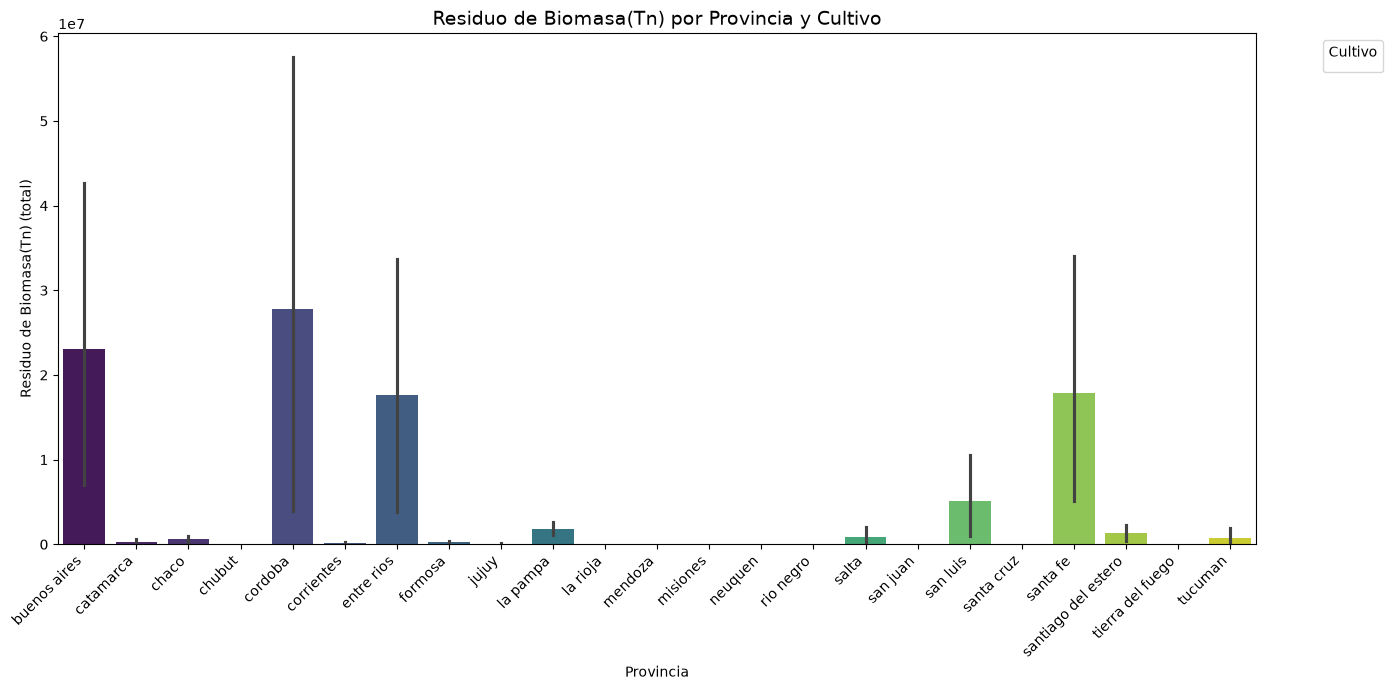

In [33]:
# Agregamos la biomasa por provincia y cultivo
df_grouped = df_biomasa.groupby(["Provincia", "Cultivo"], as_index=False)["Residuo de Biomasa(Tn)"].sum()

# Gráfico de barras
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_grouped,
    x="Provincia",
    y="Residuo de Biomasa(Tn)",
    palette="viridis"
)

plt.xticks(rotation=45, ha="right")
plt.title("Residuo de Biomasa(Tn) por Provincia y Cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa(Tn) (total)")
plt.xlabel("Provincia")
plt.legend(title="Cultivo", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Mayor Produccion de Biomasa Residual por Cultivo 

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11644\334563164.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


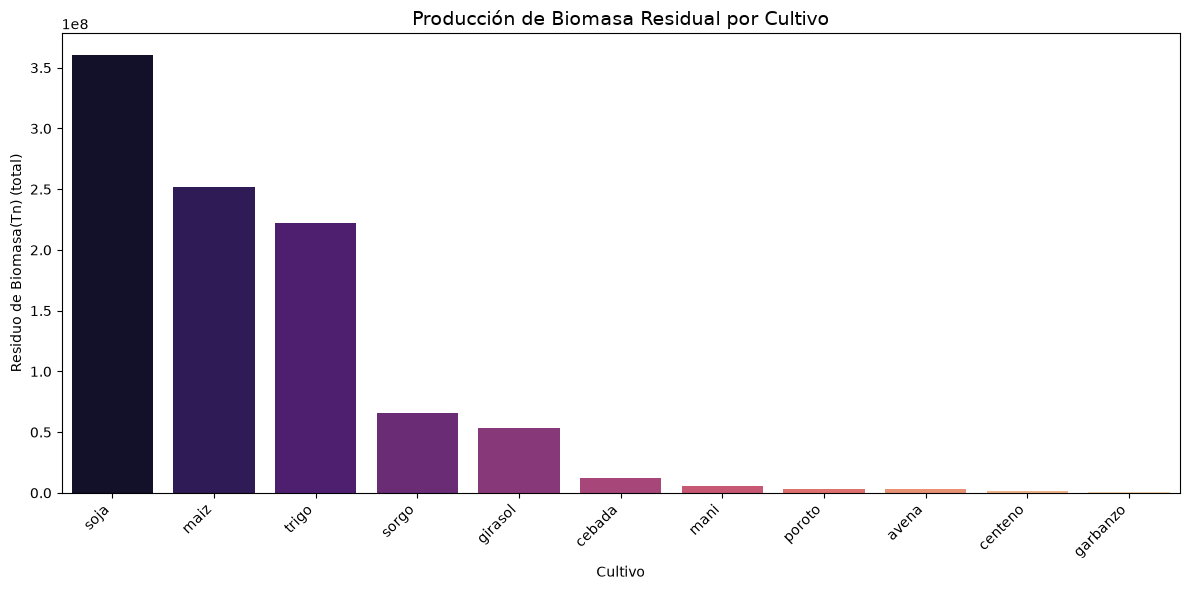

In [34]:


# Agregar biomasa por cultivo
df_cultivo = df_biomasa.groupby("Cultivo", as_index=False)["Residuo de Biomasa(Tn)"].sum()

# Ordenar de mayor a menor
df_cultivo = df_cultivo.sort_values("Residuo de Biomasa(Tn)", ascending=False)

# Gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_cultivo,
    x="Cultivo",
    y="Residuo de Biomasa(Tn)",
    palette="magma"
)

plt.xticks(rotation=45, ha="right")
plt.title("Producción de Biomasa Residual por Cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa(Tn) (total)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()
